# A4 — Estudo de Caso: Detecção de COVID-19 em Radiografias de Tórax

**Disciplina:** Visão Computacional com CNNs e Transformers

**Requisitos de execução**
- **GPU:** Colab T4 (Runtime > Change runtime type > T4 GPU).
- **Memória:** ~6 GB de RAM, ~3 GB de VRAM e ~4 GB de disco (zip de ~800 MB e imagens extraídas).
- **Tempo estimado:** ~20 a 25 minutos (download, treino da GAN condicional e 12 treinos do classificador). O tempo real é impresso na última seção.
- **Pré-requisito:** secret `KAGGLE_API_TOKEN` no Colab (ou o `.zip` do dataset na pasta do projeto no Google Drive).
- **Dataset:** [COVID-19 Radiography Database](https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database) (Chowdhury et al., 2020; Rahman et al., 2021), radiografias de tórax nas classes COVID, Normal e Viral Pneumonia.

**Uso de IA:** este notebook foi desenvolvido com apoio do assistente Claude (Anthropic) para estruturar o código e revisar os textos; a execução, a conferência e a interpretação dos resultados são da autora.

## 1. O caso e o diagnóstico

Um grupo desenvolveu um sistema de triagem de pneumonia e COVID-19 com **1.200 radiografias** em três classes (Normal: 840, Pneumonia: 240, COVID-19: 120), divisão 80/20 sem estratificação, **ResNet-18 sem pré-treinamento**, SGD com *learning rate* fixo de 0,01, 15 épocas, sem augmentation e avaliação apenas por acurácia global. Resultado: 93% de acurácia de treino e 61% de validação; o time clínico relatou que o modelo "ignora casos positivos". Nour & Tariq (2023) documentam o mesmo padrão: acurácia global alta e recall de COVID-19 inferior a 60% em bases desbalanceadas.

### Problemas técnicos identificados e impacto clínico esperado

| # | Problema | Evidência no caso | Impacto clínico esperado |
|---|---|---|---|
| 1 | **Desbalanceamento não tratado** (70% / 20% / 10%) | A perda é dominada pela classe Normal; COVID tem 120 exemplos | O modelo aprende a favorecer Normal e **deixa de detectar COVID**: falsos negativos, pacientes infectados liberados sem isolamento |
| 2 | **Métrica inadequada** (somente acurácia global) | Prever sempre "Normal" já daria 70%; os 61% de validação ficam **abaixo** desse baseline trivial se a validação mantiver a proporção | O número reportado esconde a falha na classe crítica; a decisão de implantar se apoia em uma métrica que não mede o risco clínico (faltam recall por classe, F1 macro, matriz de confusão) |
| 3 | **Divisão 80/20 sem estratificação e sem teste independente** | 20% de 120 COVID ≈ 24 casos, com proporção variável entre divisões; a "validação" é também o resultado final | Estimativa de recall instável e otimista (seleção sobre os mesmos dados), sem intervalo de confiança; risco de vazamento entre imagens do mesmo paciente |
| 4 | **Sem pré-treinamento** (ResNet-18 com ~11 M de parâmetros e 1.200 imagens) | 93% treino contra 61% validação | **Overfitting**: o modelo decora o treino e não generaliza para novos pacientes |
| 5 | **Sem augmentation** | Mesmas 1.200 imagens em todas as épocas | Memorização e fragilidade a variações de posicionamento, contraste e equipamento entre hospitais |
| 6 | **Otimização pobre** (SGD, LR fixo, 15 épocas, sem checkpoint/early stopping) | Sem *scheduler* nem seleção do melhor modelo | Modelo final é o da última época, possivelmente instável; resultados irreproduzíveis |
| 7 | **Risco de atalhos espúrios** (*shortcut learning*) em bases de COVID | Classes frequentemente vêm de fontes/equipamentos distintos | O modelo pode aprender a fonte da imagem (marcas, letras, contraste) e não a patologia, falhando em outro hospital |

Os problemas 1, 4 e 5 podem ser tratados com dados (augmentation e imagens sintéticas), o 4 e o 6 com o pipeline de treino, e o 2, o 3 e o 7 com a metodologia de avaliação.

### Abordagem escolhida: GAN condicional

Para a escassez da classe COVID-19 foi escolhida uma **GAN condicional (cGAN, estilo DCGAN)**, que recebe o rótulo da classe como condição e gera radiografias sintéticas de COVID-19. Em seguida, compara-se, em um conjunto de teste real e balanceado, o **recall da classe minoritária** entre classificadores treinados **sem** e **com** as imagens geradas. Para separar o efeito da GAN do efeito de outras melhorias, a comparação inclui quatro configurações:

1. **Caso original reproduzido** (ResNet-18 sem pré-treino, SGD fixo, sem augmentation);
2. **Pipeline melhorado, sem sintéticas** (pré-treino, augmentation, AdamW com cosseno, seleção do melhor checkpoint);
3. **Pipeline melhorado + pesos de classe** (alternativa barata ao GAN para o desbalanceamento);
4. **Pipeline melhorado + COVID-19 sintético (GAN)**.

Cada configuração é treinada com 3 sementes, e os resultados são reportados em média e desvio padrão.

## 2. Ambiente

In [17]:
import os
import sys
import glob
import math
import time
import random
import zipfile
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import sklearn
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, balanced_accuracy_score, accuracy_score

NOTEBOOK_START = time.time()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("Aviso: rodando em CPU. Selecione GPU (T4) em Runtime > Change runtime type.")

print(f"PyTorch: {torch.__version__} | Torchvision: {torchvision.__version__}")
print(f"Pandas: {pd.__version__} | NumPy: {np.__version__} | Scikit-learn: {sklearn.__version__}")

Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130
Pandas: 2.2.3 | NumPy: 2.1.3 | Scikit-learn: 1.6.1


## 3. Dataset

O download é feito pela API do Kaggle. Adicione nos *Secrets* do Colab (ícone de chave) um segredo `KAGGLE_API_TOKEN` com o token da sua conta e ative *Notebook access*. Alternativa sem token: baixe o `.zip` em https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database e coloque-o na pasta `PROJECT_DIR` do Google Drive.

In [16]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/estudos_de_caso"
os.makedirs(PROJECT_DIR, exist_ok=True)

DATA_DIR = "/content/a4_data"

try:
    from google.colab import userdata

    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"], check=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", "tawsifurrahman/covid19-radiography-database", "-p", DATA_DIR, "--unzip"],
        check=True,
    )
except Exception:
    zip_files = glob.glob(f"{PROJECT_DIR}/*.zip")
    assert zip_files, "Configure o secret KAGGLE_API_TOKEN ou coloque o .zip do dataset em PROJECT_DIR."
    with zipfile.ZipFile(zip_files[0]) as z:
        z.extractall(DATA_DIR)

print("Dataset pronto em:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset pronto em: /content/a4_data


### Montagem das divisões

O caso usa três classes: **Normal**, **Pneumonia** (a classe *Viral Pneumonia* do dataset) e **COVID-19**. Para reproduzir o cenário descrito, o **conjunto de treino** tem a mesma composição do caso: 840 Normal, 240 Pneumonia e 120 COVID-19. Como 18 casos de COVID-19 (15% de 120) seriam insuficientes para medir recall, a avaliação usa conjuntos **disjuntos e estratificados**, retirados das demais imagens do dataset:

- **Validação:** 60 imagens por classe (seleção de checkpoint);
- **Teste:** 300 imagens por classe, balanceado, usado uma única vez por modelo.

O teste balanceado permite estimar o recall de cada classe com precisão (para COVID-19, ±~5 pontos percentuais com 300 casos). As imagens são convertidas para tons de cinza e redimensionadas para **64×64**, resolução em que a GAN é treinada; o classificador usa a mesma fonte de 64×64 para imagens reais e sintéticas. O dataset não traz identificador de paciente, então não é possível garantir a separação por paciente (limitação discutida ao final).

In [18]:
CLASS_NAMES = ["Normal", "Pneumonia", "COVID-19"]
FOLDERS = {"Normal": "Normal", "Pneumonia": "Viral Pneumonia", "COVID-19": "COVID"}
TRAIN_COUNTS = {"Normal": 840, "Pneumonia": 240, "COVID-19": 120}
VAL_PER_CLASS = 60
TEST_PER_CLASS = 300
IMG = 64


def list_class_images(folder):
    paths = sorted(glob.glob(f"{DATA_DIR}/**/{folder}/images/*.png", recursive=True))
    if not paths:
        paths = sorted(glob.glob(f"{DATA_DIR}/**/{folder}/*.png", recursive=True))
    return paths


def load_gray(path):
    img = Image.open(path).convert("L").resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)


rng = np.random.RandomState(SEED)
splits = {"train": ([], []), "val": ([], []), "test": ([], [])}
available = {}

for label, name in enumerate(CLASS_NAMES):
    paths = list_class_images(FOLDERS[name])
    available[name] = len(paths)
    need = TRAIN_COUNTS[name] + VAL_PER_CLASS + TEST_PER_CLASS
    assert len(paths) >= need, f"{name}: {len(paths)} imagens, necessárias {need}."
    chosen = rng.permutation(len(paths))[:need]
    parts = {
        "train": chosen[:TRAIN_COUNTS[name]],
        "val": chosen[TRAIN_COUNTS[name]:TRAIN_COUNTS[name] + VAL_PER_CLASS],
        "test": chosen[TRAIN_COUNTS[name] + VAL_PER_CLASS:],
    }
    for split, idx in parts.items():
        splits[split][0].extend(load_gray(paths[i]) for i in idx)
        splits[split][1].extend([label] * len(idx))

data = {k: (np.stack(v[0]), np.array(v[1])) for k, v in splits.items()}
X_train, y_train = data["train"]
X_val, y_val = data["val"]
X_test, y_test = data["test"]

print("Imagens disponíveis no dataset:", available)
for k in data:
    print(f"{k:5s}: X {data[k][0].shape} | por classe {np.bincount(data[k][1]).tolist()} ({', '.join(CLASS_NAMES)})")

Imagens disponíveis no dataset: {'Normal': 10192, 'Pneumonia': 1345, 'COVID-19': 3616}
train: X (1200, 64, 64) | por classe [840, 240, 120] (Normal, Pneumonia, COVID-19)
val  : X (180, 64, 64) | por classe [60, 60, 60] (Normal, Pneumonia, COVID-19)
test : X (900, 64, 64) | por classe [300, 300, 300] (Normal, Pneumonia, COVID-19)


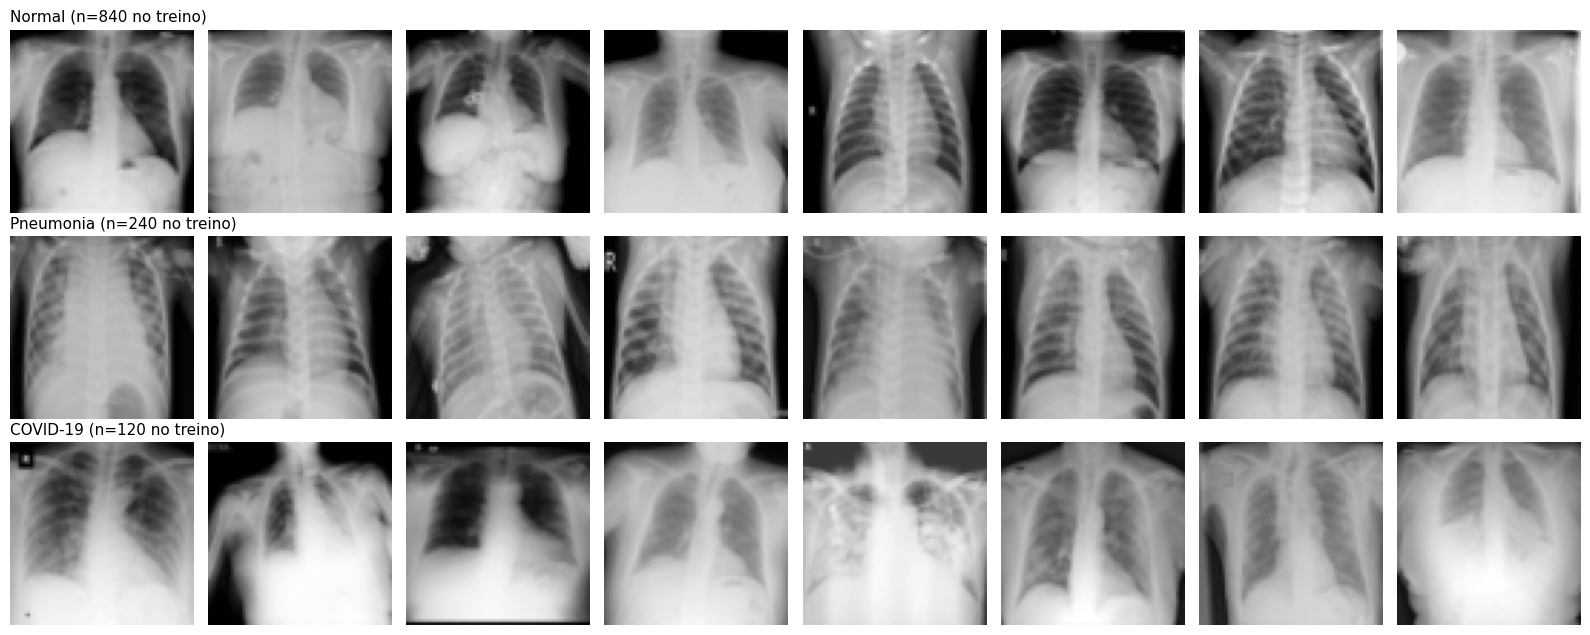

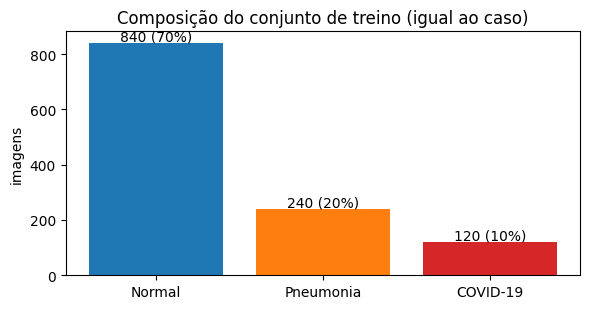

In [19]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for r, name in enumerate(CLASS_NAMES):
    idx = np.where(y_train == r)[0][:8]
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_train[i], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
    axes[r, 0].set_title(f"{name} (n={int((y_train == r).sum())} no treino)", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

counts = np.bincount(y_train)
plt.figure(figsize=(6, 3.2))
plt.bar(CLASS_NAMES, counts, color=["tab:blue", "tab:orange", "tab:red"])
for i, v in enumerate(counts):
    plt.text(i, v + 10, f"{v} ({v / counts.sum():.0%})", ha="center")
plt.title("Composição do conjunto de treino (igual ao caso)")
plt.ylabel("imagens")
plt.tight_layout()
plt.show()

## 4. GAN condicional para a classe COVID-19

**Arquitetura (cGAN em estilo DCGAN, 64×64, 1 canal).**
- **Gerador:** recebe ruído `z ∈ R^100` concatenado a um *embedding* do rótulo (3 classes), projeta para 4×4×512 e aplica quatro `ConvTranspose2d` (com BatchNorm e ReLU) até 64×64, com saída `tanh`.
- **Discriminador:** recebe a imagem concatenada com o rótulo codificado em canais (one-hot expandido para 64×64) e aplica quatro convoluções com *stride* 2, **normalização espectral** e LeakyReLU, terminando em um *logit*.

**Medidas de estabilidade, importantes com apenas 120 imagens de COVID-19:**
1. **Amostragem balanceada por classe** em cada passo, para que o gerador veja COVID-19 com a mesma frequência que Normal;
2. **Normalização espectral** no discriminador (limita a constante de Lipschitz e evita que ele domine);
3. ***Differentiable augmentation*** (brilho e translação aleatórios, aplicados às imagens reais e às geradas antes do discriminador), que reduz o *overfitting* do discriminador em dados pequenos;
4. **Rótulo suavizado** (0,9 para imagens reais) e Adam com `β1 = 0,5`;
5. Monitoramento de D(real), D(falso) e das perdas e, depois do treino, checagem de **memorização** e **diversidade** (colapso de modo).

In [20]:
Z_DIM = 100
NUM_CLASSES = 3


class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM, embed_dim=50):
        super().__init__()
        self.embed = nn.Embedding(NUM_CLASSES, embed_dim)
        self.project = nn.Sequential(
            nn.Linear(z_dim + embed_dim, 4 * 4 * 512, bias=False),
            nn.BatchNorm1d(4 * 4 * 512),
            nn.ReLU(True),
        )
        def up(i, o):
            return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
        self.net = nn.Sequential(up(512, 256), up(256, 128), up(128, 64), nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())

    def forward(self, z, labels):
        h = self.project(torch.cat([z, self.embed(labels)], dim=1)).view(-1, 512, 4, 4)
        return self.net(h)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        sn = nn.utils.spectral_norm
        self.net = nn.Sequential(
            sn(nn.Conv2d(1 + NUM_CLASSES, 64, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(64, 128, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(128, 256, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(256, 512, 4, 2, 1)), nn.LeakyReLU(0.2, True),
        )
        self.out = sn(nn.Linear(512 * 4 * 4, 1))

    def forward(self, x, labels):
        onehot = F.one_hot(labels, NUM_CLASSES).float()[:, :, None, None].expand(-1, -1, x.size(2), x.size(3))
        return self.out(self.net(torch.cat([x, onehot], dim=1)).flatten(1)).squeeze(1)


def diff_augment(x):
    b = x.size(0)
    x = x + (torch.rand(b, 1, 1, 1, device=x.device) - 0.5) * 0.4
    theta = torch.zeros(b, 2, 3, device=x.device)
    theta[:, 0, 0] = 1
    theta[:, 1, 1] = 1
    theta[:, :, 2] = (torch.rand(b, 2, device=x.device) - 0.5) * 0.25
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


print(f"Parâmetros do gerador: {count_parameters(Generator()):,} | do discriminador: {count_parameters(Discriminator()):,}")

Parâmetros do gerador: 3,999,767 | do discriminador: 2,765,761


In [21]:
GAN_STEPS = 6000
GAN_BATCH = 64

real_gan = (torch.from_numpy(X_train).float().div(127.5).sub(1.0)).unsqueeze(1).to(device)
labels_gan = torch.from_numpy(y_train).long().to(device)
sample_weights = (1.0 / torch.bincount(labels_gan).float())[labels_gan]

set_seed(SEED)
G = Generator().to(device)
D = Discriminator().to(device)
opt_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

fixed_z = torch.randn(16, Z_DIM, device=device)
fixed_labels = torch.full((16,), 2, dtype=torch.long, device=device)
snapshots = {}
log = []
running = np.zeros(4)
start = time.time()

for step in range(1, GAN_STEPS + 1):
    idx = torch.multinomial(sample_weights, GAN_BATCH, replacement=True)
    real, real_labels = real_gan[idx], labels_gan[idx]
    z = torch.randn(GAN_BATCH, Z_DIM, device=device)
    fake_labels = torch.randint(0, NUM_CLASSES, (GAN_BATCH,), device=device)
    fake = G(z, fake_labels)

    opt_d.zero_grad(set_to_none=True)
    d_real = D(diff_augment(real), real_labels)
    d_fake = D(diff_augment(fake.detach()), fake_labels)
    loss_d = bce(d_real, torch.full_like(d_real, 0.9)) + bce(d_fake, torch.zeros_like(d_fake))
    loss_d.backward()
    opt_d.step()

    opt_g.zero_grad(set_to_none=True)
    d_gen = D(diff_augment(fake), fake_labels)
    loss_g = bce(d_gen, torch.ones_like(d_gen))
    loss_g.backward()
    opt_g.step()

    running += np.array([loss_d.item(), loss_g.item(), torch.sigmoid(d_real).mean().item(), torch.sigmoid(d_fake).mean().item()])
    if step % 200 == 0:
        log.append([step] + (running / 200).tolist())
        running[:] = 0
    if step in (500, 2000, GAN_STEPS):
        G.eval()
        with torch.no_grad():
            snapshots[step] = G(fixed_z, fixed_labels).cpu()
        G.train()
    if step % 1000 == 0:
        print(f"Passo {step:5d}/{GAN_STEPS} | D: {log[-1][1]:.3f} | G: {log[-1][2]:.3f} | D(real): {log[-1][3]:.3f} | D(falso): {log[-1][4]:.3f} | {time.time() - start:.0f}s")

gan_time = time.time() - start
G.eval()
print(f"Tempo de treino da GAN: {gan_time / 60:.1f} min")

Passo  1000/6000 | D: 1.332 | G: 0.923 | D(real): 0.471 | D(falso): 0.431 | 94s
Passo  2000/6000 | D: 1.350 | G: 0.873 | D(real): 0.462 | D(falso): 0.439 | 187s
Passo  3000/6000 | D: 1.334 | G: 0.896 | D(real): 0.469 | D(falso): 0.433 | 280s
Passo  4000/6000 | D: 1.322 | G: 0.910 | D(real): 0.476 | D(falso): 0.429 | 372s
Passo  5000/6000 | D: 1.324 | G: 0.895 | D(real): 0.472 | D(falso): 0.430 | 465s
Passo  6000/6000 | D: 1.329 | G: 0.888 | D(real): 0.471 | D(falso): 0.433 | 558s
Tempo de treino da GAN: 9.3 min


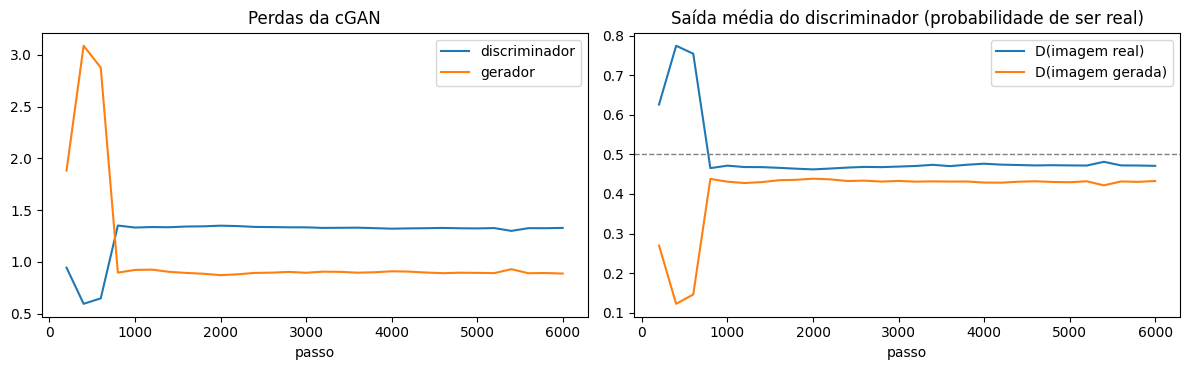

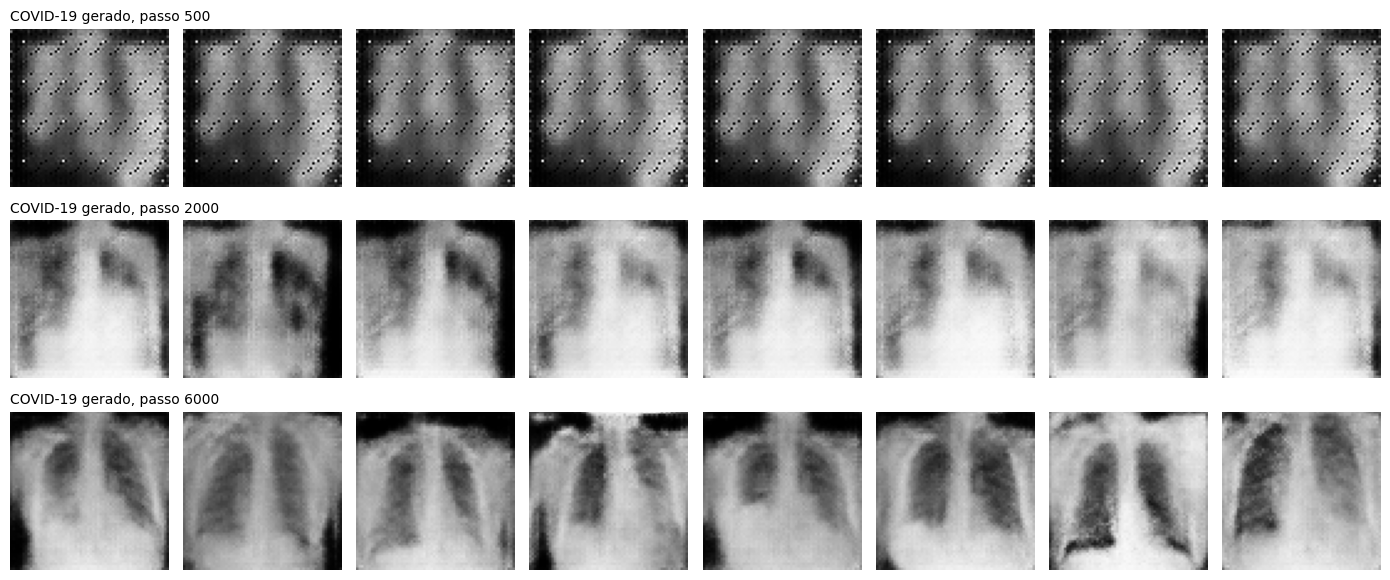

In [22]:
log_df = pd.DataFrame(log, columns=["passo", "perda D", "perda G", "D(real)", "D(falso)"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(log_df["passo"], log_df["perda D"], label="discriminador")
axes[0].plot(log_df["passo"], log_df["perda G"], label="gerador")
axes[0].set_title("Perdas da cGAN")
axes[0].set_xlabel("passo")
axes[0].legend()
axes[1].plot(log_df["passo"], log_df["D(real)"], label="D(imagem real)")
axes[1].plot(log_df["passo"], log_df["D(falso)"], label="D(imagem gerada)")
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Saída média do discriminador (probabilidade de ser real)")
axes[1].set_xlabel("passo")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(snapshots), 8, figsize=(14, 2 * len(snapshots)))
for r, (step, imgs) in enumerate(snapshots.items()):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0].numpy(), cmap="gray", vmin=-1, vmax=1)
        axes[r, c].axis("off")
    axes[r, 0].set_title(f"COVID-19 gerado, passo {step}", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### Avaliação das imagens geradas

Além da inspeção visual, são feitas duas checagens quantitativas simples sobre 300 imagens de COVID-19 geradas:

- **Memorização:** distância euclidiana (em pixels) de cada imagem gerada até a imagem de treino mais próxima, comparada com a distância entre cada imagem real de COVID-19 e sua vizinha mais próxima entre as demais reais. Distâncias geradas muito menores que as reais indicariam cópias do treino.
- **Diversidade (colapso de modo):** distância média entre pares de imagens geradas, comparada com a de pares reais. Valores muito menores indicariam que o gerador produz poucas variações.

,distância ao vizinho mais próximo (treino real),distância média entre pares
COVID-19 gerado,17.81,28.64
COVID-19 real,18.64,34.07


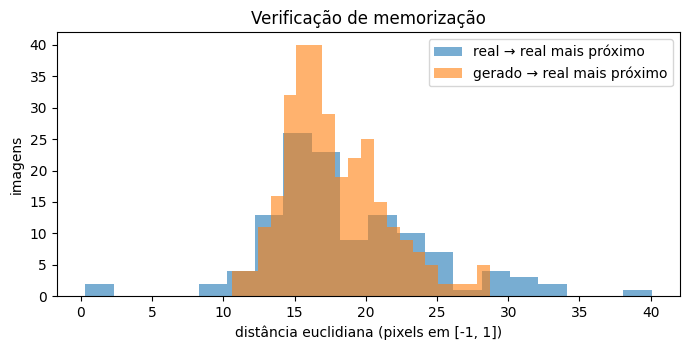

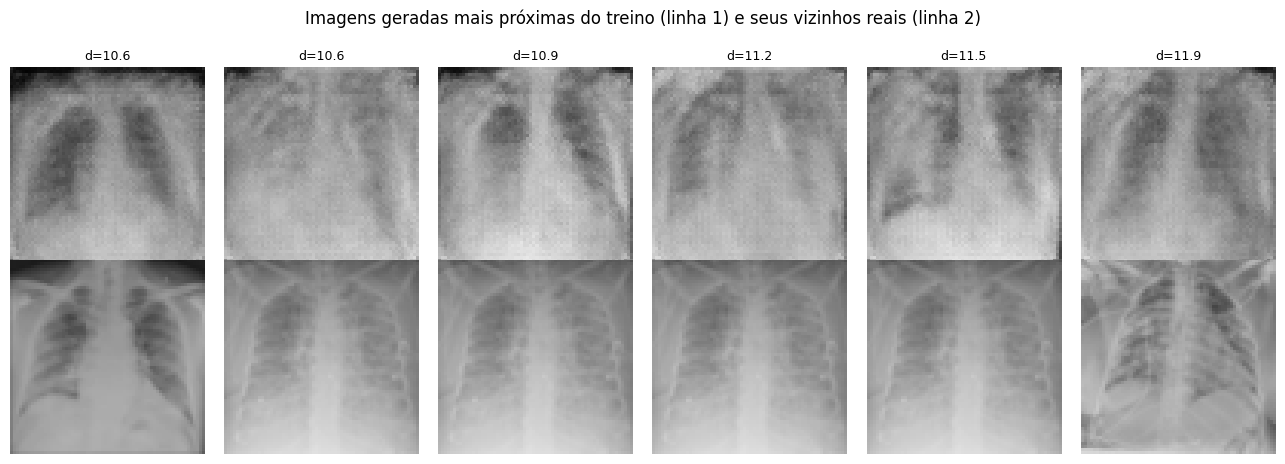

In [23]:
N_EVAL = 300
with torch.no_grad():
    z = torch.randn(N_EVAL, Z_DIM, device=device)
    eval_fake = G(z, torch.full((N_EVAL,), 2, dtype=torch.long, device=device)).squeeze(1).cpu()

real_covid = torch.from_numpy(X_train[y_train == 2]).float().div(127.5).sub(1.0)
flat_real = real_covid.flatten(1)
flat_fake = eval_fake.flatten(1)

d_fake_real = torch.cdist(flat_fake, flat_real)
nn_fake = d_fake_real.min(dim=1).values

d_real_real = torch.cdist(flat_real, flat_real)
d_real_real.fill_diagonal_(float("inf"))
nn_real = d_real_real.min(dim=1).values

pair_real = torch.pdist(flat_real).mean().item()
pair_fake = torch.pdist(flat_fake).mean().item()

summary = pd.DataFrame({
    "distância ao vizinho mais próximo (treino real)": [nn_fake.mean().item(), nn_real.mean().item()],
    "distância média entre pares": [pair_fake, pair_real],
}, index=["COVID-19 gerado", "COVID-19 real"])
display(summary.round(2))

plt.figure(figsize=(7, 3.6))
plt.hist(nn_real.numpy(), bins=20, alpha=0.6, label="real → real mais próximo")
plt.hist(nn_fake.numpy(), bins=20, alpha=0.6, label="gerado → real mais próximo")
plt.xlabel("distância euclidiana (pixels em [-1, 1])")
plt.ylabel("imagens")
plt.legend()
plt.title("Verificação de memorização")
plt.tight_layout()
plt.show()

order = nn_fake.argsort()[:6]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for c, i in enumerate(order):
    j = d_fake_real[i].argmin()
    axes[0, c].imshow(eval_fake[i], cmap="gray", vmin=-1, vmax=1)
    axes[1, c].imshow(real_covid[j], cmap="gray", vmin=-1, vmax=1)
    axes[0, c].set_title(f"d={nn_fake[i]:.1f}", fontsize=9)
    axes[0, c].axis("off")
    axes[1, c].axis("off")
axes[0, 0].set_ylabel("gerado")
fig.suptitle("Imagens geradas mais próximas do treino (linha 1) e seus vizinhos reais (linha 2)", y=1.0)
plt.tight_layout()
plt.show()

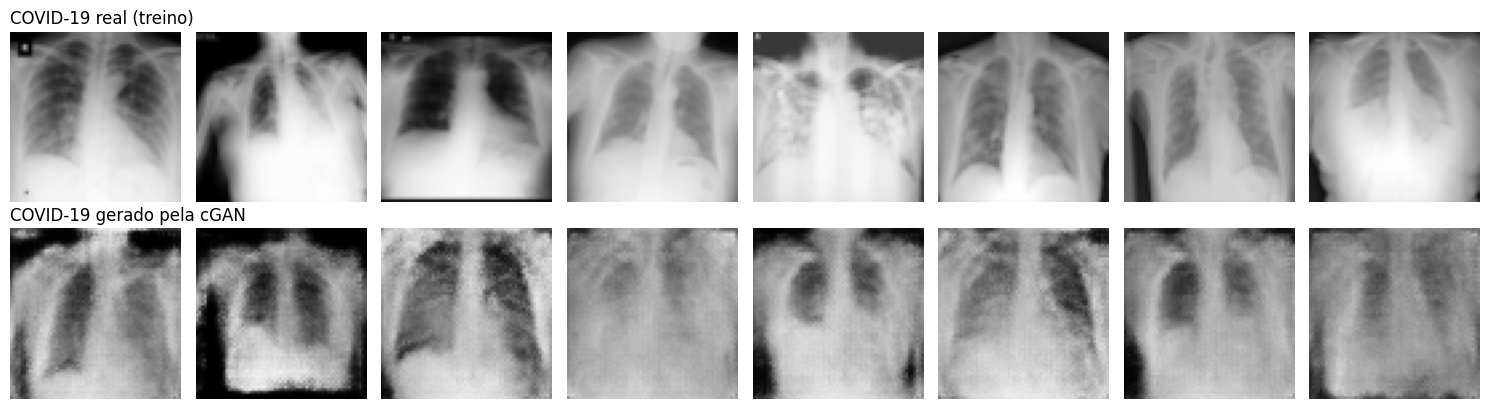

In [24]:
fig, axes = plt.subplots(2, 8, figsize=(15, 4.2))
for c in range(8):
    axes[0, c].imshow(real_covid[c], cmap="gray", vmin=-1, vmax=1)
    axes[1, c].imshow(eval_fake[c], cmap="gray", vmin=-1, vmax=1)
    axes[0, c].axis("off")
    axes[1, c].axis("off")
axes[0, 0].set_title("COVID-19 real (treino)", loc="left")
axes[1, 0].set_title("COVID-19 gerado pela cGAN", loc="left")
plt.tight_layout()
plt.show()

## 5. Classificadores e comparação com e sem imagens geradas

**Classificador:** ResNet-18. As imagens (64×64, 1 canal) são replicadas em 3 canais, redimensionadas para 128×128 e normalizadas com estatísticas do ImageNet.

**Augmentation do pipeline melhorado** (aplicada em lote na GPU): rotação de ±10°, zoom de 0,9 a 1,1, deslocamento de ±5% e variação de brilho e contraste. **Não há espelhamento horizontal**, pois inverter uma radiografia de tórax posicionaria o coração à direita, uma anatomia rara que não ocorre no dado real.

**Configurações:**

| Configuração | Pré-treino | Otimizador | Augmentation | Pesos de classe | COVID-19 sintético |
|---|---|---|---|---|---|
| 1. Caso original | não | SGD (momentum 0,9), LR 0,01 fixo, 15 épocas, última época | não | não | não |
| 2. Melhorado, sem sintéticas | ImageNet | AdamW, LR 3e-4 com cosseno, 20 épocas, melhor época na validação | sim | não | não |
| 3. Melhorado + pesos de classe | ImageNet | idem | sim | sim (inverso da frequência) | não |
| 4. Melhorado + GAN | ImageNet | idem | sim | não | +480 imagens geradas (COVID-19: 120 reais + 480 sintéticas) |

O momentum de 0,9 na configuração 1 é uma hipótese: o enunciado diz apenas "SGD". A **seleção de checkpoint usa a acurácia balanceada na validação** (real, sem imagens sintéticas). O **teste é sempre real**.

In [25]:
N_SYNTH = 480
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
CLS_SIZE = 128

with torch.no_grad():
    synth = []
    for _ in range(math.ceil(N_SYNTH / 120)):
        z = torch.randn(120, Z_DIM, device=device)
        synth.append(G(z, torch.full((120,), 2, dtype=torch.long, device=device)).squeeze(1).cpu())
    synth = torch.cat(synth)[:N_SYNTH]
X_synth = ((synth * 127.5 + 127.5).round().clamp(0, 255)).byte().numpy()
y_synth = np.full(N_SYNTH, 2)
print(f"Imagens sintéticas de COVID-19 geradas: {X_synth.shape}")


def to_gpu(x):
    return torch.from_numpy(x).to(device)


def augment_gpu(x):
    b = x.size(0)
    angle = (torch.rand(b, device=device) - 0.5) * 2 * math.radians(10)
    scale = 1.0 / torch.empty(b, device=device).uniform_(0.9, 1.1)
    theta = torch.zeros(b, 2, 3, device=device)
    theta[:, 0, 0] = torch.cos(angle) * scale
    theta[:, 0, 1] = -torch.sin(angle) * scale
    theta[:, 1, 0] = torch.sin(angle) * scale
    theta[:, 1, 1] = torch.cos(angle) * scale
    theta[:, :, 2] = (torch.rand(b, 2, device=device) - 0.5) * 0.1 * 2
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
    brightness = (torch.rand(b, 1, 1, 1, device=device) - 0.5) * 0.2
    contrast = torch.empty(b, 1, 1, 1, device=device).uniform_(0.9, 1.1)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - mean) * contrast + mean + brightness).clamp(0, 1)


def prepare(xb, train, augment):
    x = xb.float().div(255).unsqueeze(1)
    if train and augment:
        x = augment_gpu(x)
    x = F.interpolate(x, size=(CLS_SIZE, CLS_SIZE), mode="bilinear", align_corners=False)
    return (x.repeat(1, 3, 1, 1) - IMAGENET_MEAN) / IMAGENET_STD


def build_resnet(pretrained):
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def predict(model, X, batch_size=256):
    model.eval()
    preds = []
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        for i in range(0, len(X), batch_size):
            preds.append(model(prepare(X[i:i + batch_size], False, False)).argmax(1))
    return torch.cat(preds).cpu().numpy()


Xtr_real, ytr_real = to_gpu(X_train), to_gpu(y_train).long()
Xva, yva_np = to_gpu(X_val), y_val
Xte, yte_np = to_gpu(X_test), y_test

Imagens sintéticas de COVID-19 geradas: (480, 64, 64)


In [11]:
def train_classifier(X, y, seed, pretrained, optimizer_name, epochs, augment, class_weights, select_best, batch_size=64):
    set_seed(seed)
    model = build_resnet(pretrained)
    if optimizer_name == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
        scheduler = None
    else:
        optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
        total = epochs * math.ceil(len(X) / batch_size)
        scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-4, total_steps=total, pct_start=0.1)
    weight = None
    if class_weights:
        counts = torch.bincount(y, minlength=NUM_CLASSES).float()
        weight = (counts.sum() / (NUM_CLASSES * counts)).to(device)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    best_score, best_state = -1.0, None

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X), device=device)
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            if len(idx) < 2:
                continue
            xb = prepare(X[idx], True, augment)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                loss = F.cross_entropy(model(xb).float(), y[idx], weight=weight)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
        if select_best:
            score = balanced_accuracy_score(yva_np, predict(model, Xva))
            if score > best_score:
                best_score = score
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    if select_best:
        model.load_state_dict(best_state)
    return model


def evaluate_model(model):
    preds = predict(model, Xte)
    recalls = recall_score(yte_np, preds, average=None, labels=[0, 1, 2])
    return {
        "recall Normal": recalls[0],
        "recall Pneumonia": recalls[1],
        "recall COVID-19": recalls[2],
        "precisão COVID-19": precision_score(yte_np, preds, labels=[2], average=None, zero_division=0)[0],
        "F1 macro": f1_score(yte_np, preds, average="macro"),
        "acurácia balanceada": balanced_accuracy_score(yte_np, preds),
        "acurácia (teste balanceado)": accuracy_score(yte_np, preds),
        "acurácia na prevalência do caso": float(np.dot(recalls, [0.70, 0.20, 0.10])),
    }, preds


Xtr_synth_mix = torch.cat([Xtr_real, to_gpu(X_synth)])
ytr_synth_mix = torch.cat([ytr_real, to_gpu(y_synth).long()])

CONFIGS = {
    "1. Caso original": dict(X=Xtr_real, y=ytr_real, pretrained=False, optimizer_name="sgd", epochs=15, augment=False, class_weights=False, select_best=False),
    "2. Melhorado, sem sintéticas": dict(X=Xtr_real, y=ytr_real, pretrained=True, optimizer_name="adamw", epochs=20, augment=True, class_weights=False, select_best=True),
    "3. Melhorado + pesos de classe": dict(X=Xtr_real, y=ytr_real, pretrained=True, optimizer_name="adamw", epochs=20, augment=True, class_weights=True, select_best=True),
    "4. Melhorado + GAN": dict(X=Xtr_synth_mix, y=ytr_synth_mix, pretrained=True, optimizer_name="adamw", epochs=20, augment=True, class_weights=False, select_best=True),
}
SEEDS = [0, 1, 2]

rows, confusions, train_times = [], {name: np.zeros((3, 3)) for name in CONFIGS}, {}
for name, cfg in CONFIGS.items():
    t0 = time.time()
    for seed in SEEDS:
        model = train_classifier(seed=seed, **cfg)
        metrics, preds = evaluate_model(model)
        rows.append({"configuração": name, "semente": seed, **metrics})
        confusions[name] += confusion_matrix(yte_np, preds, labels=[0, 1, 2])
        del model
        torch.cuda.empty_cache()
    train_times[name] = (time.time() - t0) / len(SEEDS)
    print(f"{name}: recall COVID-19 por semente = {[round(r['recall COVID-19'], 3) for r in rows if r['configuração'] == name]} | {train_times[name]:.0f}s por treino")

results = pd.DataFrame(rows)

1. Caso original: recall COVID-19 por semente = [np.float64(0.393), np.float64(0.437), np.float64(0.373)] | 11s por treino
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]
/tmp/ipykernel_2961/1338315486.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


2. Melhorado, sem sintéticas: recall COVID-19 por semente = [np.float64(0.793), np.float64(0.78), np.float64(0.617)] | 15s por treino


/tmp/ipykernel_2961/1338315486.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/tmp/ipykernel_2961/1338315486.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/tmp/ipykernel_2961/1338315486.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimize

3. Melhorado + pesos de classe: recall COVID-19 por semente = [np.float64(0.763), np.float64(0.733), np.float64(0.84)] | 15s por treino


/tmp/ipykernel_2961/1338315486.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/tmp/ipykernel_2961/1338315486.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


4. Melhorado + GAN: recall COVID-19 por semente = [np.float64(0.627), np.float64(0.693), np.float64(0.663)] | 21s por treino


### Resultados no conjunto de teste (real, balanceado: 300 imagens por classe)

,recall COVID-19,recall Pneumonia,recall Normal,precisão COVID-19,F1 macro,acurácia balanceada,acurácia na prevalência do caso
configuração,,,,,,,
1. Caso original,0.401 ± 0.032,0.940 ± 0.012,0.974 ± 0.002,0.935 ± 0.013,0.755 ± 0.017,0.772 ± 0.014,0.910 ± 0.005
"2. Melhorado, sem sintéticas",0.730 ± 0.098,0.947 ± 0.010,0.981 ± 0.010,0.983 ± 0.007,0.885 ± 0.032,0.886 ± 0.030,0.949 ± 0.006
3. Melhorado + pesos de classe,0.779 ± 0.055,0.964 ± 0.020,0.963 ± 0.038,0.978 ± 0.024,0.902 ± 0.022,0.902 ± 0.021,0.945 ± 0.024
4. Melhorado + GAN,0.661 ± 0.033,0.940 ± 0.020,0.992 ± 0.005,0.997 ± 0.003,0.863 ± 0.009,0.864 ± 0.008,0.949 ± 0.004


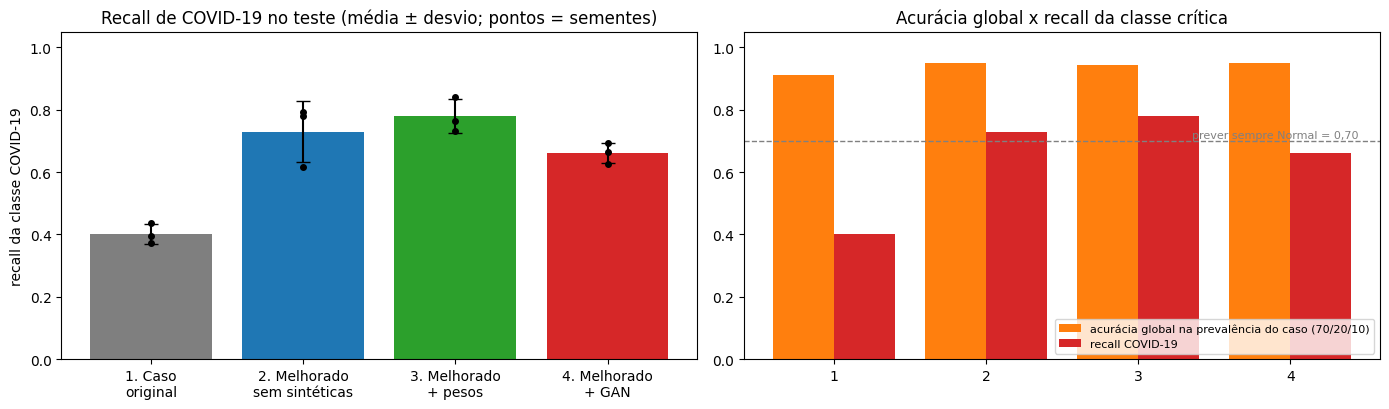

In [12]:
metric_cols = ["recall COVID-19", "recall Pneumonia", "recall Normal", "precisão COVID-19", "F1 macro", "acurácia balanceada", "acurácia na prevalência do caso"]
agg = results.groupby("configuração")[metric_cols].agg(["mean", "std"])
table = pd.DataFrame({c: [f"{agg.loc[i, (c, 'mean')]:.3f} ± {agg.loc[i, (c, 'std')]:.3f}" for i in agg.index] for c in metric_cols}, index=agg.index)
display(table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
names = list(CONFIGS.keys())
means = [results[results["configuração"] == n]["recall COVID-19"].mean() for n in names]
stds = [results[results["configuração"] == n]["recall COVID-19"].std() for n in names]
axes[0].bar(range(4), means, yerr=stds, capsize=5, color=["tab:gray", "tab:blue", "tab:green", "tab:red"])
for i, seed_vals in enumerate([results[results["configuração"] == n]["recall COVID-19"].values for n in names]):
    axes[0].scatter([i] * len(seed_vals), seed_vals, color="black", s=16, zorder=3)
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(["1. Caso\noriginal", "2. Melhorado\nsem sintéticas", "3. Melhorado\n+ pesos", "4. Melhorado\n+ GAN"])
axes[0].set_ylabel("recall da classe COVID-19")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Recall de COVID-19 no teste (média ± desvio; pontos = sementes)")

acc_bal = [results[results["configuração"] == n]["acurácia balanceada"].mean() for n in names]
acc_prev = [results[results["configuração"] == n]["acurácia na prevalência do caso"].mean() for n in names]
x = np.arange(4)
axes[1].bar(x - 0.2, acc_prev, 0.4, label="acurácia global na prevalência do caso (70/20/10)", color="tab:orange")
axes[1].bar(x + 0.2, means, 0.4, label="recall COVID-19", color="tab:red")
axes[1].axhline(0.70, color="gray", linestyle="--", linewidth=1)
axes[1].text(3.45, 0.71, "prever sempre Normal = 0,70", ha="right", fontsize=8, color="gray")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["1", "2", "3", "4"])
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=8, loc="lower right")
axes[1].set_title("Acurácia global x recall da classe crítica")
plt.tight_layout()
plt.show()

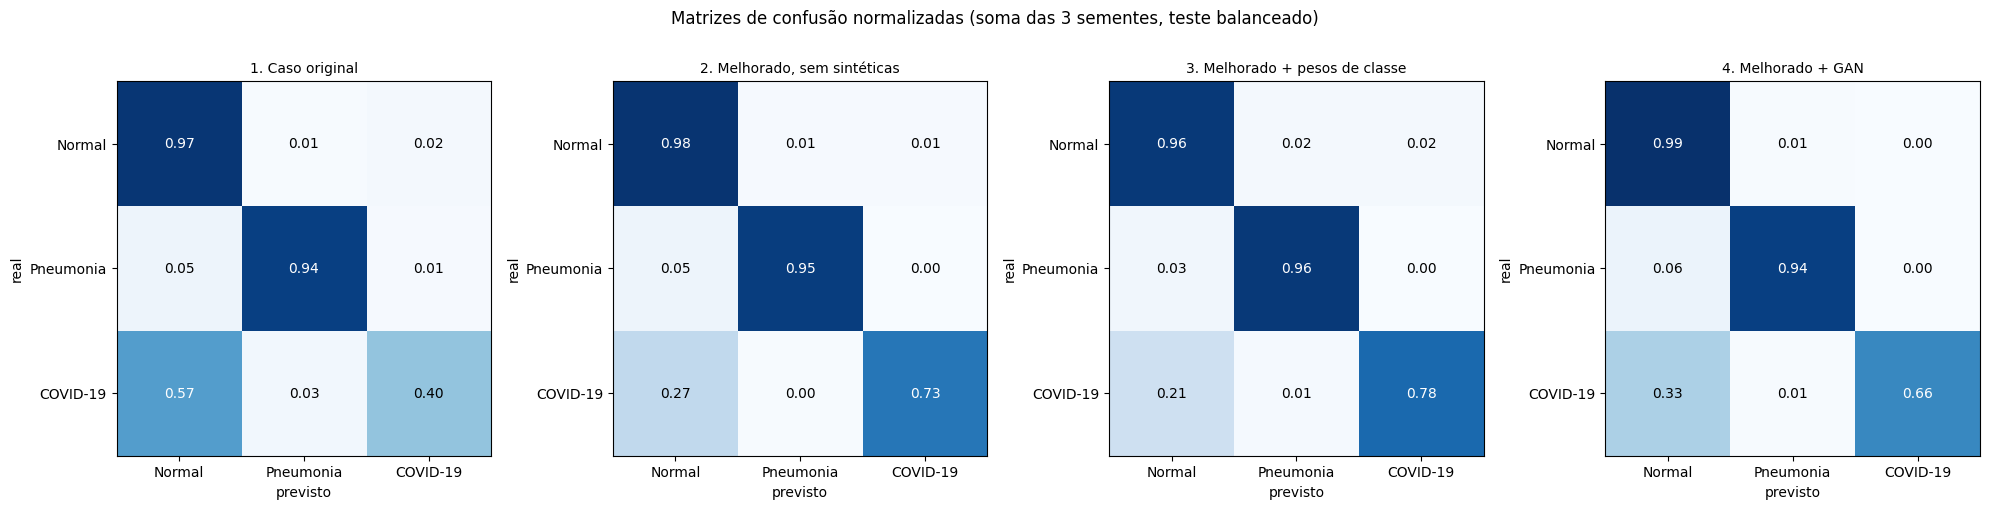

configuração,1. Caso original,"2. Melhorado, sem sintéticas",3. Melhorado + pesos de classe,4. Melhorado + GAN
semente,,,,
0,0.393,0.793,0.763,0.627
1,0.437,0.780,0.733,0.693
2,0.373,0.617,0.840,0.663


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, (name, cm) in zip(axes, confusions.items()):
    norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
    ax.set_title(name, fontsize=10)
plt.suptitle("Matrizes de confusão normalizadas (soma das 3 sementes, teste balanceado)", y=1.03)
plt.tight_layout()
plt.show()

per_seed = results.pivot(index="semente", columns="configuração", values="recall COVID-19")
display(per_seed.round(3))

In [14]:
r2 = results[results["configuração"] == "2. Melhorado, sem sintéticas"]["recall COVID-19"]
r3 = results[results["configuração"] == "3. Melhorado + pesos de classe"]["recall COVID-19"]
r4 = results[results["configuração"] == "4. Melhorado + GAN"]["recall COVID-19"]
r1 = results[results["configuração"] == "1. Caso original"]["recall COVID-19"]
print(f"Recall COVID-19 (média das 3 sementes): caso original {r1.mean():.3f} | melhorado {r2.mean():.3f} | + pesos {r3.mean():.3f} | + GAN {r4.mean():.3f}")
print(f"Efeito do pipeline melhorado (2 vs 1): {100 * (r2.mean() - r1.mean()):+.1f} p.p.")
print(f"Efeito da GAN sobre o pipeline melhorado (4 vs 2): {100 * (r4.mean() - r2.mean()):+.1f} p.p.")
print(f"GAN vs pesos de classe (4 vs 3): {100 * (r4.mean() - r3.mean()):+.1f} p.p.")
print(f"Tempo médio por treino: " + " | ".join(f"{k.split('.')[0]}: {v:.0f}s" for k, v in train_times.items()))

Recall COVID-19 (média das 3 sementes): caso original 0.401 | melhorado 0.730 | + pesos 0.779 | + GAN 0.661
Efeito do pipeline melhorado (2 vs 1): +32.9 p.p.
Efeito da GAN sobre o pipeline melhorado (4 vs 2): -6.9 p.p.
GAN vs pesos de classe (4 vs 3): -11.8 p.p.
Tempo médio por treino: 1: 11s | 2: 15s | 3: 15s | 4: 21s


## 6. Plano de melhoria integrado

O plano abaixo endereça cada um dos sete problemas identificados, com a ação, a métrica que comprova o ganho e o que foi **efetivamente testado neste notebook**.

| # | Problema | Ação proposta | Métrica de verificação | Testado aqui |
|---|---|---|---|---|
| 1 | Desbalanceamento | Pesos de classe na perda; amostragem balanceada; imagens sintéticas de COVID-19 (cGAN) limitadas a um teto (aqui 480 para 120 reais); coleta de mais casos reais | Recall de COVID-19 e matriz de confusão | Sim (configurações 3 e 4) |
| 2 | Métrica inadequada | Relatar recall e precisão **por classe**, F1 macro, acurácia balanceada e matriz de confusão; definir um recall mínimo para COVID-19 antes da implantação; ajustar o limiar de decisão à curva precisão-recall | Recall por classe com intervalo de confiança | Sim (tabelas e gráficos) |
| 3 | Divisão sem estratificação | Divisão estratificada e **por paciente**, com treino, validação e teste independentes; teste usado uma única vez; várias sementes ou validação cruzada | Desvio padrão entre sementes; intervalo de confiança do recall | Parcial (estratificado, 3 sementes; o dataset não tem ID de paciente) |
| 4 | Sem pré-treinamento / overfitting | Transfer learning (ImageNet ou modelos pré-treinados em radiografias), regularização (*weight decay*) | Gap treino-validação; recall no teste | Sim (configuração 2 vs 1) |
| 5 | Sem augmentation | Augmentation clinicamente plausível (rotação, zoom, brilho e contraste; **sem espelhamento**); augmentation sintética por GAN | Recall e estabilidade entre sementes | Sim |
| 6 | Otimização pobre | AdamW com *warmup* e decaimento cosseno, seleção do melhor *checkpoint* pela métrica da classe crítica (acurácia balanceada), *early stopping* | Curva de validação por época; reprodutibilidade | Sim |
| 7 | Atalhos espúrios | Validação **externa** em outro hospital/equipamento; mapas de saliência (Grad-CAM) para confirmar que o modelo olha para os pulmões; harmonização de contraste; documentar a origem de cada classe | Desempenho em dados de outra fonte; saliência nas regiões pulmonares | Não (exige dados externos) |

**Riscos específicos das imagens sintéticas:** (i) elas **nunca devem entrar no conjunto de validação ou teste**, e aqui foram usadas apenas no treino; (ii) a GAN pode memorizar as 120 imagens (checado pela distância ao vizinho mais próximo) ou colapsar em poucos modos (checado pela diversidade); (iii) imagens sintéticas não substituem validação clínica nem coleta de casos reais; (iv) artefatos do gerador podem virar um atalho novo (o classificador aprender "textura de GAN = COVID-19"), e por isso o teste com imagens exclusivamente reais é obrigatório.

## 7. Tempo total, referências e declaração de uso de IA

In [15]:
total = time.time() - NOTEBOOK_START
print(f"Tempo total de execução do notebook: {total / 60:.1f} min (GAN: {gan_time / 60:.1f} min)")
if device.type == "cuda":
    print(f"Pico de memória de GPU alocada: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

Tempo total de execução do notebook: 13.3 min (GAN: 9.3 min)
Pico de memória de GPU alocada: 0.7 GB


### Referências

- Nour, M.; Tariq, M. (2023). *Scientific Reports*. https://www.nature.com/articles/s41598-023-37743-4
- Chowdhury, M. E. H. et al. (2020). *Can AI help in screening Viral and COVID-19 pneumonia?* IEEE Access, 8.
- Rahman, T. et al. (2021). *Exploring the effect of image enhancement techniques on COVID-19 detection using chest X-ray images.* Computers in Biology and Medicine, 132.
- Goodfellow, I. et al. (2014). *Generative Adversarial Nets.* NeurIPS.
- Mirza, M.; Osindero, S. (2014). *Conditional Generative Adversarial Nets.* arXiv:1411.1784.
- Radford, A.; Metz, L.; Chintala, S. (2016). *Unsupervised Representation Learning with Deep Convolutional GANs.* ICLR.
- Miyato, T. et al. (2018). *Spectral Normalization for Generative Adversarial Networks.* ICLR.
- Zhao, S. et al. (2020). *Differentiable Augmentation for Data-Efficient GAN Training.* NeurIPS.
- He, K. et al. (2016). *Deep Residual Learning for Image Recognition.* CVPR.
- Dataset: Rahman, T.; Chowdhury, M. *COVID-19 Radiography Database.* Kaggle. https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database

### Declaração de uso de IA

Este notebook foi desenvolvido com apoio do assistente de IA Claude (Anthropic), utilizado para estruturar o código e redigir os textos de análise.